# `Материалы кафедры ММП факультета ВМК МГУ. Введение в эффективные системы глубокого обучения`

# `Семинар 05. Triton`

## `Занятие провел: Феоктистов Дмитрий`

## `Материалы составил: Оганов Александр (tg: @welmud)`

### `Москва, Осенний семестр 2026`

Источники:

- [PyTorch документация](https://docs.pytorch.org/docs/stable/index.html)

- [Triton документация](https://triton-lang.org/main/index.html)

- [CS336 Language Modeling from Scratch](https://youtu.be/xnDHaNUvHBg?si=G_txz4e5bt5ksaf-)

- [Некоторые задачи взяты из GitHub](https://github.com/deep-spin/triton-tutorial/)

- [GitHub для задач на Triton](https://github.com/gpu-mode/Triton-Puzzles/blob/main/Triton-Puzzles.ipynb)

---

In [1]:
import torch
import torch.nn.functional as F
from torch import FloatTensor
from torch.profiler import profile, ProfilerActivity

import triton
import triton.language as tl

import numpy as np
import random

In [2]:
def set_global_seed(seed: int) -> None:
    """Set global seed for reproducibility.
    :param int seed: Seed to be set
    """
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.use_deterministic_algorithms(False)

set_global_seed(42)

In [3]:
print("PyTorch:", torch.__version__)
print("CUDA available:", is_cuda:=torch.cuda.is_available())
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(f"Device is {DEVICE}")

torch.set_default_device(DEVICE)
torch.cuda.set_device(DEVICE)
if is_cuda:
    device_properties = torch.cuda.get_device_properties(0)  # device index
    print(f"Device name: {device_properties.name}")
    print(f"Device total memory: {device_properties.total_memory / 2 ** 20} MB")

PyTorch: 2.9.0+cu130
CUDA available: True
Device is cuda:0
Device name: NVIDIA GeForce RTX 2060
Device total memory: 5737.75 MB


Возьмём код с семинара по профилированию, только добавим прогрев, так как мы будем много компилировать на сегоднящнем занятии.

In [4]:
from tqdm import trange
from statistics import mean, stdev
import time
    
def microbench_this_func(iterations: int = 100, num_warmups: int = 10):
    is_benchmarked = False

    def outer_wrapper(func):
        
        def wrapper(*args, **kwargs):
            nonlocal is_benchmarked
            name = func.__name__
            if not is_benchmarked:
                measurements = []
                for _ in trange(iterations + num_warmups, desc=f"Benchmarking {name}"):
                    start = torch.cuda.Event(enable_timing=True)
                    end = torch.cuda.Event(enable_timing=True)

                    start.record()
                    func(*args, **kwargs)
                    end.record()
                    torch.cuda.synchronize()  # wait the processes

                    measurements.append(start.elapsed_time(end) / 1000)
                is_benchmarked = True  # mark the function and not benchmark later

                # summarize the report:
                mean_time = mean(measurements)
                std_time = stdev(measurements)
                print(f'Function {func} took {mean_time:.5f}+-{std_time:.5f}s')
                
                mean_time = mean(measurements[num_warmups:])
                std_time = stdev(measurements[num_warmups:])
                print(f'Function {func} after warmup took {mean_time:.5f}+-{std_time:.5f}s')

            res = func(*args, **kwargs)
            return res
        return wrapper    
    return outer_wrapper

Как на семинаре по профилированию попробуем провести benchmarking для GeLU с аппроксимацией `tanh`.

$$ \text{GELU}(x) = 0.5 * x * (1 + \text{Tanh}(\sqrt{2 / \pi} * (x + 0.044715 * x^3)))$$


In [5]:
from math import sqrt

@microbench_this_func()
def handmade_gelu(x):
    tanh_arg = sqrt(2 / torch.pi) * (x + 0.044715 * x * x * x)
    return 0.5 * x * (1 + torch.tanh(tanh_arg))

@microbench_this_func()
@torch.compile
def handmade_gelu_compiled(x):
    return handmade_gelu(x)
    
@microbench_this_func()
def pytorch_gelu(x):
    return torch.nn.functional.gelu(x, approximate='tanh')

In [6]:
set_global_seed(42)
a = torch.randn(16384).cuda()

In [7]:
out_base = handmade_gelu(a)

Benchmarking handmade_gelu: 100%|█████████████████████| 110/110 [00:00<00:00, 3260.73it/s]

Function <function handmade_gelu at 0x7fcd3de45120> took 0.00027+-0.00142s
Function <function handmade_gelu at 0x7fcd3de45120> after warmup took 0.00014+-0.00005s


In [8]:
out_pytorch = pytorch_gelu(a)

Benchmarking pytorch_gelu: 100%|██████████████████████| 110/110 [00:00<00:00, 9312.96it/s]

Function <function pytorch_gelu at 0x7fcd1dbb0860> took 0.00008+-0.00054s
Function <function pytorch_gelu at 0x7fcd1dbb0860> after warmup took 0.00003+-0.00000s


In [9]:
out_compiled = handmade_gelu_compiled(a)

Benchmarking handmade_gelu_compiled: 100%|██████████████| 110/110 [00:01<00:00, 89.91it/s]

Function <function handmade_gelu_compiled at 0x7fcd1dba8fe0> took 0.01108+-0.11465s
Function <function handmade_gelu_compiled at 0x7fcd1dba8fe0> after warmup took 0.00015+-0.00001s


In [10]:
torch.testing.assert_close(out_base, out_pytorch, atol=1e-4, rtol=1e-4)
torch.testing.assert_close(out_compiled, out_pytorch, atol=1e-4, rtol=1e-4)

Почему такое отличие?

In [11]:
with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as base_prof:
    handmade_gelu(a)
torch.cuda.synchronize()

with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as compiled_prof:
    handmade_gelu_compiled(a)
torch.cuda.synchronize()

with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as pytorch_prof:
    pytorch_gelu(a)
torch.cuda.synchronize()

In [12]:
def print_prof(prof):
    print(prof.key_averages().table(sort_by="cuda_time_total",
                                      max_name_column_width=100,
                                      row_limit=10))

In [13]:
print_prof(base_prof)

--------------  ------------  ------------  ------------  ------------  ------------  ------------  
          Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
--------------  ------------  ------------  ------------  ------------  ------------  ------------  
     aten::mul        95.30%       1.286ms        95.30%       1.286ms     214.389us             6  
     aten::add         3.19%      43.049us         3.19%      43.049us      21.524us             2  
    aten::tanh         1.51%      20.323us         1.51%      20.323us      20.323us             1  
--------------  ------------  ------------  ------------  ------------  ------------  ------------  
Self CPU time total: 1.350ms



In [14]:
print_prof(compiled_prof)

-----------------------------------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                                               Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-----------------------------------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                         Torch-Compiled Region: 0/0         6.06%      87.494us        97.66%       1.411ms       1.411ms       0.000us         0.00%       2.496us       2.496us             1  
    ## Call CompiledFxGraph fbu2gieuh6qlm7edp44gcipqx4xd6frcbjxput3ujbpkiblbnibf ##         9.0

In [15]:
print_prof(pytorch_prof)

----------------------------------------------------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                                                                Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
----------------------------------------------------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                                                          aten::gelu         2.19%      33.537us        75.42%       1.155ms       1.155ms       3.136us       100.00%       6.272us       6.272us             1  
                           

## Напоминание предворительных сведений

### Модель памяти

- Thread: выполняет код на малом размере данных
    
- Thread block или concurrent thread array (CTA): группа Threads
    
- Grid: коллекция Thread blocks

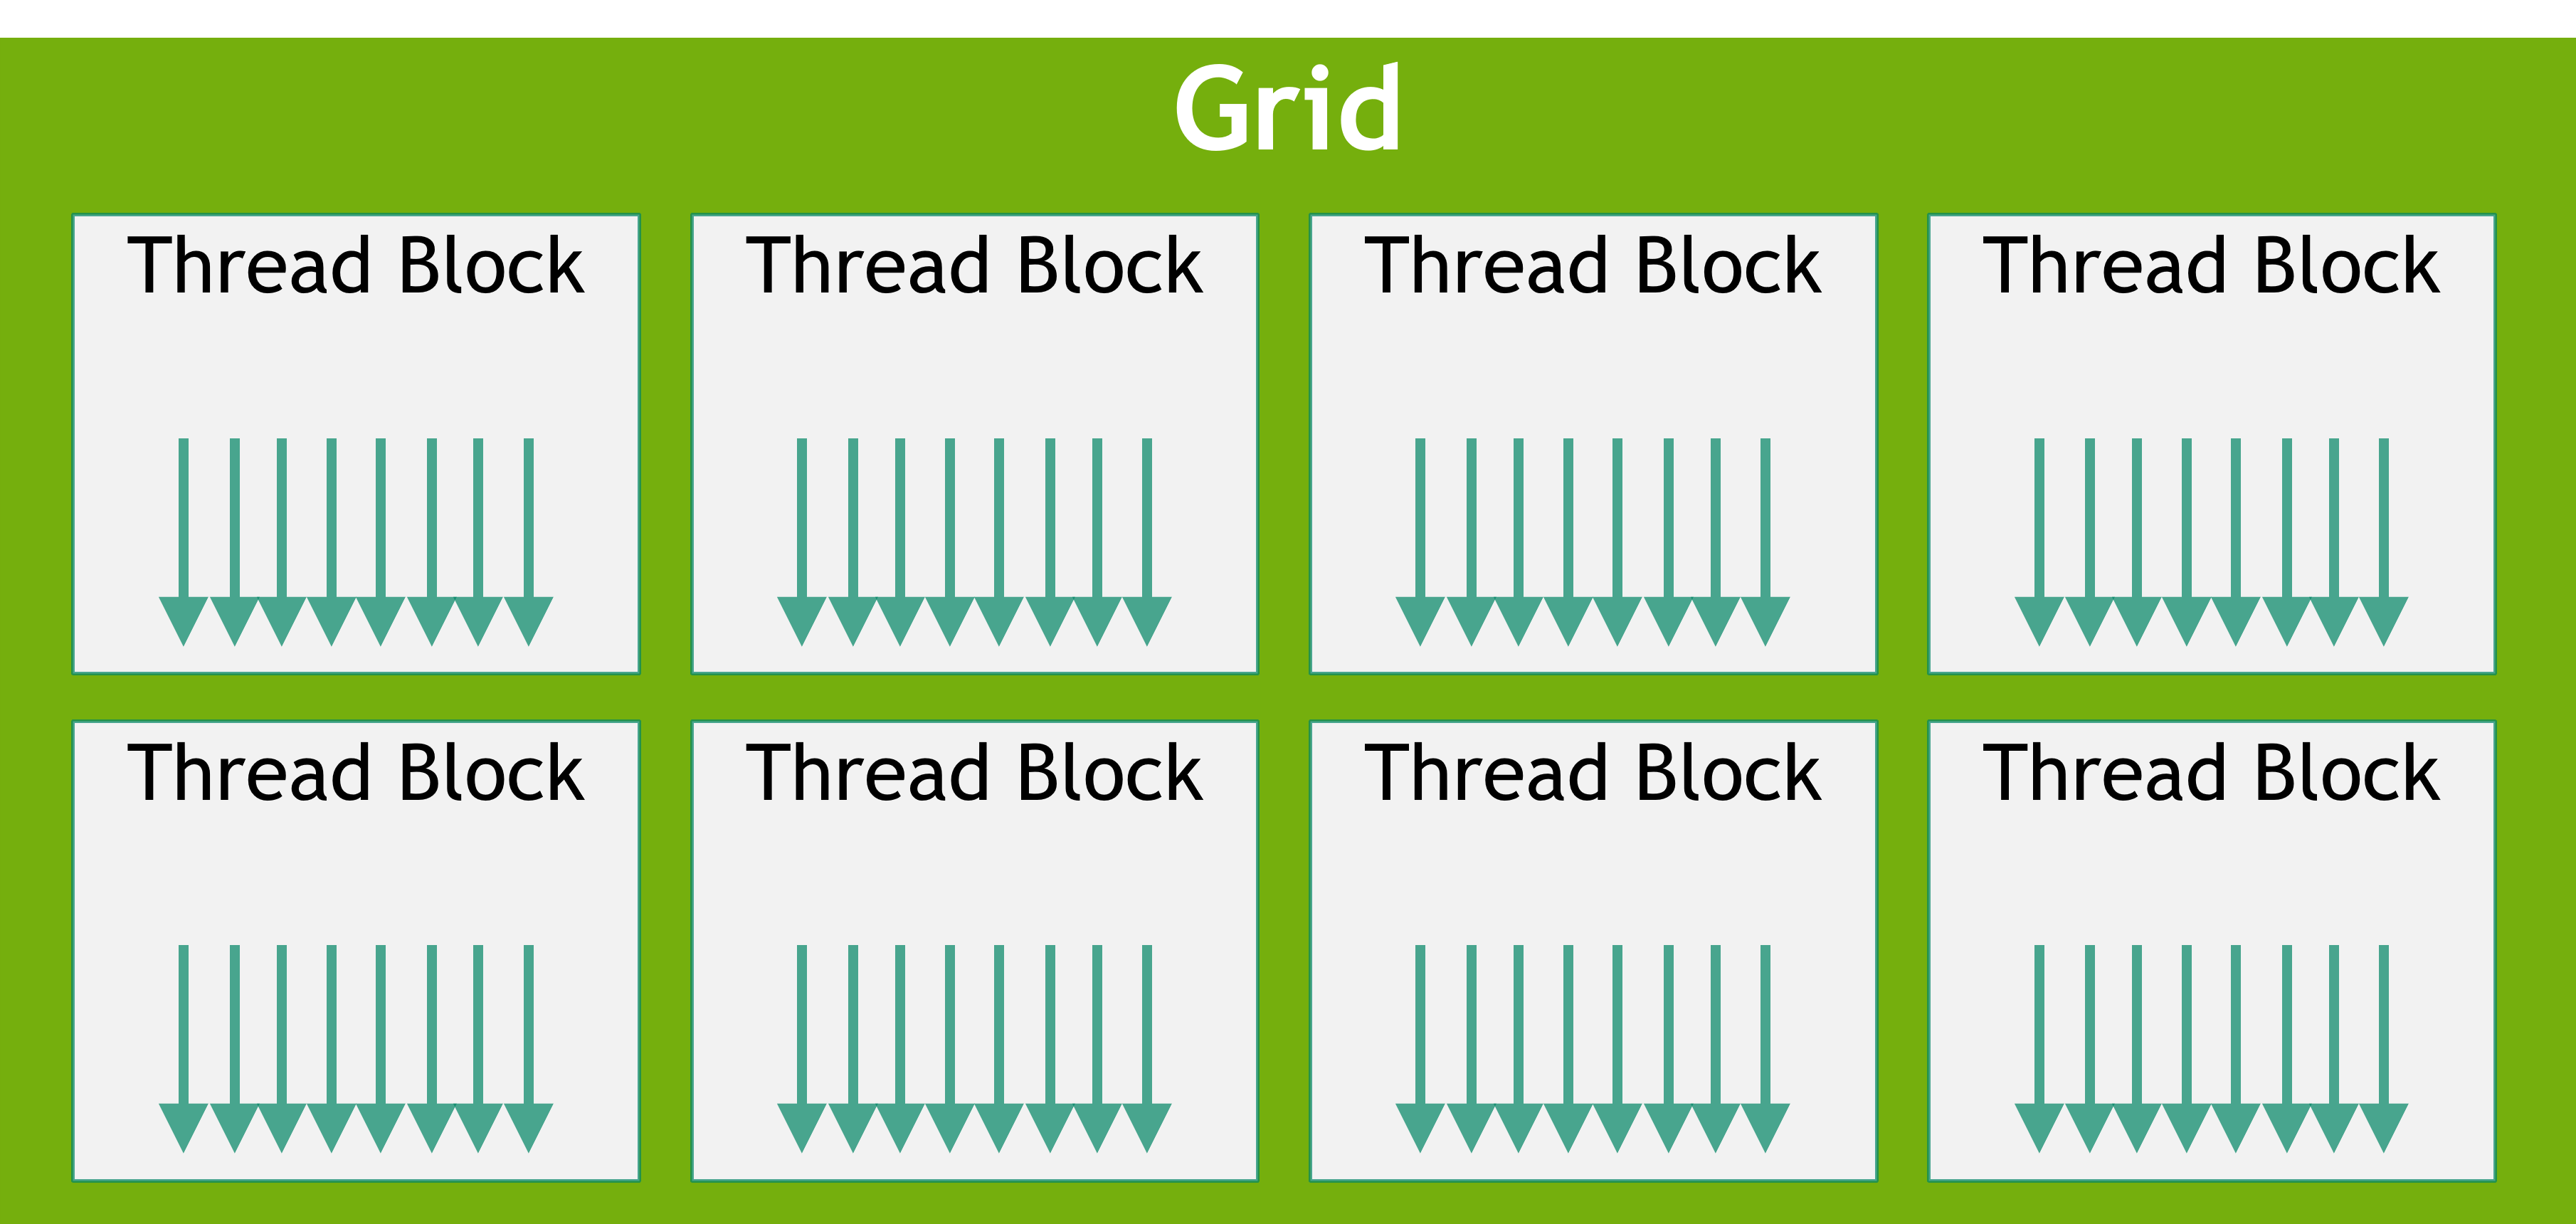

[Источник](https://docs.nvidia.com/cuda/cuda-programming-guide/01-introduction/programming-model.html)

Идейно наш код будет устроен следующим образом:

1) Разбили задачу на какое-то количество независимых подзадач размера `BLOCK_SIZE`

2) Вызвали для каждой задачи kernel

3) Внутри kernel сделали вычисление. Каждый kernel знает в каком  Thread block он находится (`triton.language.program_id(axis=0)`) и размер `BLOCK_SIZE`

Напоминание: нам крайне желательно избегать ветвлений внутри kernel.

Часто для сокращения пишут:

```python
import triton.language as tl
```

### Как лежат тензоры в памяти

Ниже мы будем работать с памятью более низкоуровнево, а именно, через указатели, поэтому важно, чтобы данные у нас лежали в памяти последовательно. Иногда, мы можем это пропустить, так как PyTorch часто не меняет порядок данных, а меняет view. Для проверки `torch.tensor` мы можем использовать `.is_contiguous()`.

In [16]:
B = torch.arange(12).reshape(3, 4)
print("Strides:", B.stride())       
print("Contiguous:", B.is_contiguous())

Strides: (4, 1)
Contiguous: True


In [17]:
C = B.T           
print("Strides:", C.stride())        
print("Contiguous:", C.is_contiguous())  

Strides: (1, 4)
Contiguous: False


К счастью, это просто исправить.

In [18]:
C = C.contiguous()
print("Strides:", C.stride())
print("Contiguous:", C.is_contiguous())

Strides: (3, 1)
Contiguous: True


Далее мы всегда будем вызывать `.contiguous()` для всех тензоров, перед тем как применять к ним ядра.

### Пример стандартного ядра

Мы будем писать все ядра в следующем стиле:

```python
@triton.jit
def foo_kernel(
    x_ptr,  # Pointer to first input vector
    x_size, # Size of first vector
    y_ptr,  # Pointer to second input vector
    y_size, # Size of second vector
    ...
    output_ptr,  # Pointer to output vector
    n_elements,  # Size of output vector
    BLOCK_SIZE: tl.constexpr,  # Number of elements each program processes
):
    # Your code here

    
```

`@triton.jit` декоратор, который переводит все аргументы у которых есть метод `.data_ptr()` и аттрибут `.dtype` в указатели. Кроме того, функция будет скомпилирована и запущена на CUDA. Подробнее в [документации](https://triton-lang.org/main/python-api/generated/triton.jit.html).

Естественно, если размеры векторов на входе и выходе равны, то мы не обязаны дублировать размеры, но при работе с указателями нам **важно** знать размер вектора и не залезть за его границы.

Функцию `foo_kernel` мы вызываем не совсем обычно. Обратите внимание на `BLOCK_SIZE: tl.constexpr`. С помощью `tl.constexpr` мы указываем конфигурацию компиляции. Мы будем вызывать вызывать `foo_kernel[...](args, BLOCK_SIZE=...)`, так как `BLOCK_SIZE` константа компиляции, она передасться внутрь и мы скомпилируем код с учётом `BLOCK_SIZE`. Такой механизм, чем-то похож на шаблоны в C++. Соотвественно меняя `BLOCK_SIZE` мы будем получать разный скопмпилрованный код и разную эффективность.

Вызов ядра происходит следующим образом:

```python
def foo_triton(x: torch.Tensor, y: torch.Tensor, ..., output_size: int) -> torch.Tensor:
    # Ensure inputs are contiguous and on the correct device
    x = x.contiguous()
    y = y.contiguous()
    ...
    
    # Allocate output tensor
    output = torch.empty_like(output_size)
    
    # Get the number of elements
    n_elements = output.numel()
    
    # Define block size (must be power of 2)
    BLOCK_SIZE = 1024  # we can optimize this!
    
    # Calculate grid size (number of programs to launch)
    #cdiv = ceil division
    grid = lambda meta: (triton.cdiv(n_elements, meta['BLOCK_SIZE']),)  
    
    # Launch kernel
    foo_kernel[grid](
        x, output, n_elements,
        BLOCK_SIZE=BLOCK_SIZE,
    )
    
    return output
```

## Сложение векторов

Для начала попробуем сложить два вектора.

In [19]:
@microbench_this_func()
def add_pytorch(x, y):
    return x + y

In [20]:
@microbench_this_func()
@torch.compile
def add_pytorch_compiled(x, y):
    return x + y

Теперь попробуем сделать с помощью triton. Мы складываем тензоры одного размера, кроме того выход у нас того же размера что и вход. Значит мы можем чуть упростить код. Зададим параметр `BLOCK_SIZE` как аргумент функции, так как далее посмотрим как он влияет на код.

In [21]:
def add_triton(x: torch.Tensor, y: torch.Tensor,  BLOCK_SIZE: int = 1024) -> torch.Tensor:
    """
    Wrapper function for the Triton vector addition kernel.
    Handles output allocation and kernel launching.
    """
    # Ensure inputs are contiguous and on the correct device
    x = x.contiguous()
    y = y.contiguous()
    
    # Allocate output tensor
    output = torch.empty_like(x)
    
    # Get the number of elements
    n_elements = output.numel()
    
    # Calculate grid size (number of programs to launch)
    #cdiv = ceil division
    grid = lambda meta: (triton.cdiv(n_elements, meta['BLOCK_SIZE']),)  
    
    # Launch kernel
    add_kernel[grid](
        x, y, output, n_elements,
        BLOCK_SIZE=BLOCK_SIZE,
    )
    
    return output

В целом, наш код готов, осталось написать `kernel`. Наш код запускается внутри разных Thread block их номер мы можем узнать по номеру процесса, в котором запущен `kernel`:

```python
pid = tl.program_id(axis=0)
```

Внутри функции, которая обернута в декоратор `@triton.jit` мы можем использовать только:

- примитивы Python,

- встроенные функции в triton,

- аргументы функции,

- иные функции с этим декоратором.

Для чтения из памяти используем:

```python
tl.load(start_ptr, mask=mask, other=0.0)
```

Функция считает `len(mask)` элементов, начнет с указателя `start_ptr`, где `mask` принимает `True` мы считаем значения, иначе оставим `other`.

Для записи в память аналогично:

```python
tl.store(output_ptr, tensor_for_output, mask=mask)
```

In [22]:
@triton.jit
def add_kernel(x_ptr, y_ptr, output_ptr, n_elements, BLOCK_SIZE: tl.constexpr):
    """
    Triton kernel for element-wise vector addition.
    Each program instance processes BLOCK_SIZE elements.
    """
    # Identify which program we are
    pid = tl.program_id(axis=0)
    
    # Calculate the starting index for this program
    block_start = pid * BLOCK_SIZE
    
    # Create a range of offsets for this block
    offsets = block_start + tl.arange(0, BLOCK_SIZE)
    
    # Create a mask to guard against out-of-bounds accesses
    mask = offsets < n_elements
    
    # Load x and y from HBM to SRAM
    x = tl.load(x_ptr + offsets, mask=mask, other=0.0)
    y = tl.load(y_ptr + offsets, mask=mask, other=0.0)
    
    # Perform the addition on SRAM
    output = x + y
    
    # Write the result back to HBM
    tl.store(output_ptr + offsets, output, mask=mask)

Обратите внимание, что внутри kernel мы работаем с SRAM, а чтение и запись это коммуникации между `SRAM` и `HBM`. 

In [23]:
set_global_seed(42)

x = torch.randn(1000000).cuda()
y = torch.randn(1000000).cuda()

In [24]:
base_output = add_pytorch(x, y)

Benchmarking add_pytorch: 100%|███████████████████████| 110/110 [00:00<00:00, 8809.54it/s]

Function <function add_pytorch at 0x7fcd1308d8a0> took 0.00007+-0.00001s
Function <function add_pytorch at 0x7fcd1308d8a0> after warmup took 0.00007+-0.00001s


In [25]:
compile_output = add_pytorch_compiled(x, y)

Benchmarking add_pytorch_compiled: 100%|██████████████| 110/110 [00:00<00:00, 1545.69it/s]

Function <function add_pytorch_compiled at 0x7fcd1308e5c0> took 0.00060+-0.00456s
Function <function add_pytorch_compiled at 0x7fcd1308e5c0> after warmup took 0.00017+-0.00000s


In [26]:
torch.testing.assert_close(base_output, compile_output, atol=1e-4, rtol=1e-4)

Сначала просто запустим код, проверим, что он не упадет.

In [27]:
triton_output = add_triton(x, y)

In [28]:
torch.testing.assert_close(base_output, triton_output, atol=1e-4, rtol=1e-4)

Мы справились, теперь сделаем замеры.

In [29]:
triton_output = microbench_this_func()(add_triton)(x, y)
torch.testing.assert_close(base_output, triton_output, atol=1e-4, rtol=1e-4)

Benchmarking add_triton: 100%|████████████████████████| 110/110 [00:00<00:00, 6256.42it/s]

Function <function add_triton at 0x7fcd1dba9d00> took 0.00012+-0.00005s
Function <function add_triton at 0x7fcd1dba9d00> after warmup took 0.00012+-0.00001s


Обратите внимание, если мы поменяем `BLOCK_SIZE`, то нам снова потребуется время на компиляцию (это видно по замерам с и без прогрева)

In [30]:
triton_output = microbench_this_func()(lambda x, y: add_triton(x, y, BLOCK_SIZE=512))(x, y)
torch.testing.assert_close(base_output, triton_output, atol=1e-4, rtol=1e-4)

Benchmarking <lambda>: 100%|██████████████████████████| 110/110 [00:00<00:00, 5679.70it/s]


Function <function <lambda> at 0x7fcd08f89800> took 0.00014+-0.00018s
Function <function <lambda> at 0x7fcd08f89800> after warmup took 0.00012+-0.00002s


In [31]:
triton_output = microbench_this_func()(lambda x, y: add_triton(x, y, BLOCK_SIZE=512))(x, y)
torch.testing.assert_close(base_output, triton_output, atol=1e-4, rtol=1e-4)

Benchmarking <lambda>: 100%|██████████████████████████| 110/110 [00:00<00:00, 5949.98it/s]

Function <function <lambda> at 0x7fcd08f89e40> took 0.00013+-0.00002s
Function <function <lambda> at 0x7fcd08f89e40> after warmup took 0.00013+-0.00002s


По коду `kernel` очень удобно посчитать число операций.

In [32]:
def count_flops(n_elements):
    """
    Count FLOPs for vector addition.
    
    Vector addition performs 1 addition per element.
    """
    return n_elements

def analyze_memory_ops(n_elements):
    """
    Analyze memory operations for vector addition.
    
    Returns:
        dict: Memory operations breakdown
    """
    return {
        'reads': 2 * n_elements,  # Read x and y
        'writes': n_elements,     # Write output
        'total': 3 * n_elements,  # Total memory ops
        'arithmetic_intensity': 1/3  # FLOPs per memory op
    }

# Test FLOP counting
n = x.shape[0]
flops = count_flops(n)
mem_ops = analyze_memory_ops(n)

print(f"Vector addition for {n:,} elements:")
print(f"  FLOPs: {flops:,}")
print(f"  Memory reads: {mem_ops['reads']:,}")
print(f"  Memory writes: {mem_ops['writes']:,}")
print(f"  Total memory ops: {mem_ops['total']:,}")
print(f"  Arithmetic intensity: {mem_ops['arithmetic_intensity']:.3f} FLOPs/byte")

Vector addition for 1,000,000 elements:
  FLOPs: 1,000,000
  Memory reads: 2,000,000
  Memory writes: 1,000,000
  Total memory ops: 3,000,000
  Arithmetic intensity: 0.333 FLOPs/byte


## LayerNorm

Пусть $\mathbf{x} \in \mathbb{R}^{N \times D}$ (батч размера $N$, размерность признаков $D$):

$$\text{LayerNorm}(\mathbf{x}_i) = \gamma \odot \frac{\mathbf{x}_i - \mu_i}{\sqrt{\sigma_i^2 + \epsilon}} + \beta,$$
где $i$:
- $\mu_i = \frac{1}{D} \sum_{j=1}^{D} x_{ij}$ (среднее по фичам)
- $\sigma_i^2 = \frac{1}{D} \sum_{j=1}^{D} (x_{ij} - \mu_i)^2$ (дисперсия по фичам)
- $\gamma, \beta \in \mathbb{R}^D$ обучаемые scale и shift
- $\epsilon$ константа для численной стабильности


Напишем код из PyTorch.

In [33]:
def layernorm_pytorch(x, weight, bias, eps=1e-5):
    """PyTorch's built-in LayerNorm."""
    return F.layer_norm(x, x.shape[-1:], weight, bias, eps)

Напишем свою реализацию:

In [34]:
def handmade_layernorm(x, weight, bias, eps=1e-5):
    """
    Naive two-pass implementation of LayerNorm.
    First pass: compute mean
    Second pass: compute variance
    Third pass: normalize
    """
    # Assume x is (N, D) where we normalize over D
    mean = x.mean(dim=-1, keepdim=True)  # (N, 1)
    var = ((x - mean) ** 2).mean(dim=-1, keepdim=True)  # (N, 1)
    std = torch.sqrt(var + eps)
    # Normalize
    x_norm = (x - mean) / std
    # Scale and shift
    return weight * x_norm + bias

Также рассмотрим скомпилированный код.

In [35]:
@torch.compile
def handmade_layernorm_compiled(x, weight, bias, eps=1e-5):
    return handmade_layernorm(x, weight, bias, eps)

Для вычислений суммы и иных редукций, мы будем использовать `tl.reduce`.

```python
# Sum reduction along axis 0
sum_val = tl.sum(data, axis=0)

# You can also use tl.reduce with custom operations
mean_val = tl.sum(data, axis=0) / num_elements
```

Мы предположим, что у нас $D$ меньше `BLOCK_SIZE` чтобы мы могли обрабатывать все фичи за раз.

In [36]:
@triton.jit
def layernorm_kernel_naive(
    x_ptr, y_ptr, weight_ptr, bias_ptr,
    N, D,
    eps: tl.constexpr,
    BLOCK_SIZE: tl.constexpr
):
    """LayerNorm kernel - each program handles one sample."""
    # Program ID = which sample (row) we're processing
    row = tl.program_id(0)
    
    # Base pointers for this row
    x_row_ptr = x_ptr + row * D
    y_row_ptr = y_ptr + row * D
    
    # First pass: compute mean and variance
    # We'll accumulate in chunks of BLOCK_SIZE
    mean = 0.0

    # Create offset mask
    offs = tl.arange(0, BLOCK_SIZE)
    mask = offs < D    
    # Load chunk of input
    x = tl.load(x_row_ptr + offs, mask=mask, other=0.0)
    # Accumulate sum for mean
    mean += tl.sum(x, axis=0)
    # Compute mean
    mean = mean / D

    var = 0.0
    # Second pass: compute variance
    offs = tl.arange(0, BLOCK_SIZE)
    mask = offs < D
    # Load chunk
    x = tl.load(x_row_ptr + offs, mask=mask, other=0.0)
    # Accumulate variance
    diff = x - mean
    var += tl.sum(diff * diff, axis=0)
    
    # Compute variance and standard deviation
    var = var / D
    std = tl.sqrt(var + eps)
    
    # Third pass: normalize and write output
    offs = tl.arange(0, BLOCK_SIZE)
    mask = offs < D
    
    # Load input, weight, and bias
    x = tl.load(x_row_ptr + offs, mask=mask, other=0.0)
    w = tl.load(weight_ptr + offs, mask=mask, other=1.0)
    b = tl.load(bias_ptr + offs, mask=mask, other=0.0)
    
    # Normalize
    x_norm = (x - mean) / std
    
    # Scale and shift
    y = w * x_norm + b
    
    # Store output
    tl.store(y_row_ptr + offs, y, mask=mask)

In [37]:
def layernorm_triton(x, weight, bias, eps=1e-5, kernel=layernorm_kernel_naive):
    """Wrapper for the Triton LayerNorm kernel."""
    assert x.is_contiguous()
    assert weight.is_contiguous() 
    assert bias.is_contiguous()
    
    N, D = x.shape
    
    # Allocate output
    y = torch.empty_like(x)
    
    # Choose block size (must be power of 2)
    BLOCK_SIZE = triton.next_power_of_2(min(D, 1024))
    
    # Launch grid: one program per sample
    grid = (N,)
    
    # Launch kernel
    kernel[grid](
        x, y, weight, bias,
        N, D,
        eps,
        BLOCK_SIZE
    )
    
    return y

In [38]:
set_global_seed(42)

N = 32
D = 256

x = torch.randn(N, D).cuda()
weight = torch.randn(D).cuda()
bias = torch.randn(D).cuda()
eps = 1e-5

In [39]:
# Compute with PyTorch
expected = layernorm_pytorch(x, weight, bias, eps)

In [40]:
# Compute with Triton
actual = layernorm_triton(x, weight, bias, eps)

In [41]:
torch.testing.assert_close(actual, expected, atol=1e-4, rtol=1e-4)

In [42]:
_ = microbench_this_func()(handmade_layernorm)(x, weight, bias, eps)

Benchmarking handmade_layernorm: 100%|████████████████| 110/110 [00:00<00:00, 1346.05it/s]

Function <function handmade_layernorm at 0x7fcd08f89bc0> took 0.00070+-0.00455s
Function <function handmade_layernorm at 0x7fcd08f89bc0> after warmup took 0.00026+-0.00004s


In [43]:
_ = microbench_this_func()(handmade_layernorm_compiled)(x, weight, bias, eps)

Benchmarking handmade_layernorm_compiled: 100%|████████| 110/110 [00:00<00:00, 855.22it/s]

Function <function handmade_layernorm_compiled at 0x7fcd08f8af20> took 0.00112+-0.00976s
Function <function handmade_layernorm_compiled at 0x7fcd08f8af20> after warmup took 0.00019+-0.00001s


In [44]:
_ = microbench_this_func()(layernorm_triton)(x, weight, bias, eps)

Benchmarking layernorm_triton: 100%|██████████████████| 110/110 [00:00<00:00, 6585.03it/s]

Function <function layernorm_triton at 0x7fcd08f89a80> took 0.00011+-0.00004s
Function <function layernorm_triton at 0x7fcd08f89a80> after warmup took 0.00011+-0.00004s


In [45]:
_ = microbench_this_func()(layernorm_pytorch)(x, weight, bias, eps)

Benchmarking layernorm_pytorch: 100%|█████████████████| 110/110 [00:00<00:00, 9543.55it/s]

Function <function layernorm_pytorch at 0x7fcd08f8a0c0> took 0.00007+-0.00001s
Function <function layernorm_pytorch at 0x7fcd08f8a0c0> after warmup took 0.00006+-0.00000s


Пока мы проигрываем PyTorch. Но давайте чуть модифицируем нашу реализацию для фичей произвольного размера. В наш код добавится только циклы по оси фичей.

In [46]:
@triton.jit
def layernorm_kernel(
    x_ptr, y_ptr, weight_ptr, bias_ptr,
    N, D,
    eps: tl.constexpr,
    BLOCK_SIZE: tl.constexpr
):
    """LayerNorm kernel - each program handles one sample."""
    # Program ID = which sample (row) we're processing
    row = tl.program_id(0)
    
    # Base pointers for this row
    x_row_ptr = x_ptr + row * D
    y_row_ptr = y_ptr + row * D
    
    # First pass: compute mean and variance
    # We'll accumulate in chunks of BLOCK_SIZE
    mean = 0.0
    var = 0.0
    
    for start_idx in range(0, D, BLOCK_SIZE):
        # Create offset mask
        offs = start_idx + tl.arange(0, BLOCK_SIZE)
        mask = offs < D
        
        # Load chunk of input
        x = tl.load(x_row_ptr + offs, mask=mask, other=0.0)
        
        # Accumulate sum for mean
        mean += tl.sum(x, axis=0)
    
    # Compute mean
    mean = mean / D
    
    # Second pass: compute variance
    for start_idx in range(0, D, BLOCK_SIZE):
        offs = start_idx + tl.arange(0, BLOCK_SIZE)
        mask = offs < D
        
        # Load chunk
        x = tl.load(x_row_ptr + offs, mask=mask, other=0.0)
        
        # Accumulate variance
        diff = x - mean
        var += tl.sum(diff * diff, axis=0)
    
    # Compute variance and standard deviation
    var = var / D
    std = tl.sqrt(var + eps)
    
    # Third pass: normalize and write output
    for start_idx in range(0, D, BLOCK_SIZE):
        offs = start_idx + tl.arange(0, BLOCK_SIZE)
        mask = offs < D
        
        # Load input, weight, and bias
        x = tl.load(x_row_ptr + offs, mask=mask, other=0.0)
        w = tl.load(weight_ptr + offs, mask=mask, other=1.0)
        b = tl.load(bias_ptr + offs, mask=mask, other=0.0)
        
        # Normalize
        x_norm = (x - mean) / std
        
        # Scale and shift
        y = w * x_norm + b
        
        # Store output
        tl.store(y_row_ptr + offs, y, mask=mask)


In [47]:
set_global_seed(42)

N = 32
D = 4096

x = torch.randn(N, D).cuda()
weight = torch.randn(D).cuda()
bias = torch.randn(D).cuda()
eps = 1e-5

In [48]:
# Compute with PyTorch
expected = layernorm_pytorch(x, weight, bias, eps)

In [49]:
# Compute with Triton
actual = layernorm_triton(x, weight, bias, eps, kernel=layernorm_kernel)

In [50]:
torch.testing.assert_close(actual, expected, atol=1e-4, rtol=1e-4)

### Сравнение скорости

Для бенчмаркинга в triton есть специальный декоратор.

Running benchmarks...


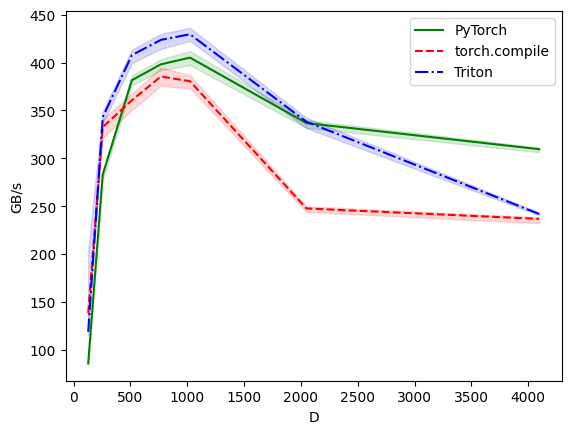

layernorm-performance:
        D     PyTorch  torch.compile      Triton
0   128.0   85.892531     138.553913  118.940108
1   256.0  283.092870     332.670049  343.120420
2   512.0  381.577879     360.583216  407.688954
3   768.0  398.193437     385.505895  423.724127
4  1024.0  405.168483     380.470242  429.568217
5  2048.0  336.837782     247.714631  338.250313
6  4096.0  309.588431     236.819145  241.983731


In [51]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['D'],  # Feature dimension
        x_vals=[128, 256, 512, 768, 1024, 2048, 4096],
        line_arg='provider',
        line_vals=['pytorch', 'handmad-compile', 'triton'],
        line_names=['PyTorch', 'torch.compile', 'Triton'],
        styles=[('green', '-'), ('red', '--'), ('blue', '-.')],
        ylabel='GB/s',
        plot_name='layernorm-performance',
        args={'N': 1024},  # Batch size
    )
)
def benchmark(D, N, provider):
    """Benchmark LayerNorm."""
    x = torch.randn(N, D, device=DEVICE, dtype=torch.float32)
    weight = torch.randn(D, device=DEVICE, dtype=torch.float32)
    bias = torch.randn(D, device=DEVICE, dtype=torch.float32)
    
    quantiles = [0.5, 0.05, 0.95]
    
    if provider == 'pytorch':
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: layernorm_pytorch(x, weight, bias), quantiles=quantiles
        )
    elif provider == 'handmad-compile':
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: handmade_layernorm_compiled(x, weight, bias), quantiles=quantiles
        )
    elif provider == 'triton':
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: layernorm_triton(x, weight, bias, kernel=layernorm_kernel), quantiles=quantiles
        )
    
    # Calculate bandwidth
    bytes_moved = x.numel() * x.element_size() * 2  # Read + write
    bytes_moved += weight.numel() * weight.element_size() * N  # Weight read N times
    bytes_moved += bias.numel() * bias.element_size() * N  # Bias read N times
    
    gb_per_s = lambda ms: bytes_moved / ms / 1e6
    
    return gb_per_s(ms), gb_per_s(max_ms), gb_per_s(min_ms)

print("Running benchmarks...")
results = benchmark.run(show_plots=True, print_data=True, return_df=True, save_path='')

In [53]:
# Check if Triton is faster than PyTorch
avg_pytorch = results['PyTorch'].mean()
avg_triton = results['Triton'].mean()
speedup = avg_triton / avg_pytorch

if speedup > 1.0:
    print(f"\n Triton быстрее PyTorch в {speedup:.2f}x раза!")
else:
    print(f"\nTriton медленее PyTorch в {speedup:.2f}x раза!")


 Triton быстрее PyTorch в 1.05x раза!


Правда, мы не умеем через нашу реализацию считать градиенты по параметрам и обучать их.